# [기초-실습] 통계 101×데이터 분석: (7장) 상관과 회귀

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비

### 1단계 · 한글 폰트 설치

- 그래프에 한글이 깨지지 않도록 나눔 폰트를 설치합니다.

- 실행 후 **[런타임] - [세션 다시 시작]**을 한 번 눌러야 폰트가 적용됩니다.

In [2]:
import platform
import warnings
warnings.filterwarnings('ignore')

# OS별 한글 폰트 설정 (Windows: 맑은 고딕 / Mac: AppleGothic / 그외(Colab 등): 나눔고딕)
if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:
    plt.rcParams['font.family'] = 'NanumGothic'

plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

### 2단계 · 라이브러리 불러오기

- 이번 실습에서 쓰는 도구입니다. **한 번만 실행**해 두면 끝까지 사용합니다.

- `smf`는 회귀식을 `'y ~ x'` 형태로 쓰는 모듈, `het_breuschpagan`은 등분산 검정 함수입니다.

In [ ]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan

## 문제 1 · 펭귄의 부리는 길수록 두꺼울까?

`난이도 하` · `예상 15분`

**📖 상황**

- 남극 팔머 기지에서 측정한 펭귄 344마리의 신체 데이터(`penguins`)를 사용합니다.

- 부리 길이(`bill_length_mm`)와 부리 두께(`bill_depth_mm`)가 함께 어떻게 움직이는지 봅니다.

- 그런데 이 데이터에는 **세 종(Adelie·Chinstrap·Gentoo)이 섞여 있습니다.**
  전체를 뭉쳐서 볼 때와 집단을 나눠서 볼 때 **결론이 정반대로 뒤집히는 일**이 실제로 일어납니다.

**🎯 이 문제로 배우는 것**

- 상관계수를 계산하기 **전에** 산점도를 먼저 그려야 하는 이유를, 숫자로 직접 확인합니다.

In [3]:
# 문제 1 · 데이터 준비 — 실행만 하세요
penguins = sns.load_dataset('penguins')

print("데이터 크기:", penguins.shape)
print("\n종별 개체 수:")
print(penguins['species'].value_counts())
print("\n결측치 개수:")
print(penguins.isna().sum())

penguins.head()

데이터 크기: (344, 7)

종별 개체 수:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

결측치 개수:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


### Q1 · 산점도로 두 변수의 관계를 그려 봅시다

- 가로축 `bill_length_mm`, 세로축 `bill_depth_mm`로 산점도를 그리세요.

- 그래프 제목과 축 라벨을 한글로 알아보기 쉽게 설정하세요.

- `💡 힌트` `sns.scatterplot(data=..., x=..., y=...)` / `plt.title()`, `plt.xlabel()`, `plt.ylabel()`

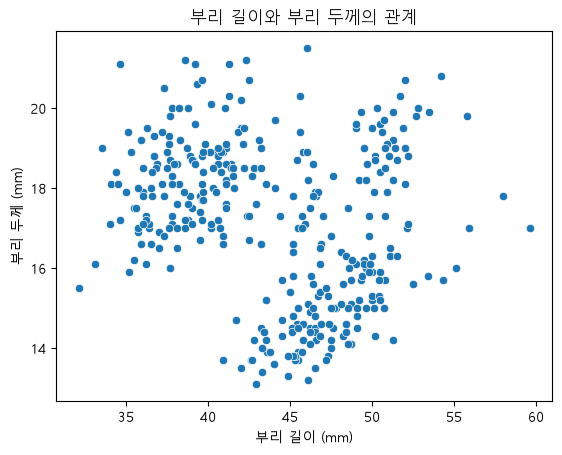

In [4]:
# 문제 1 · Q1

sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm')
plt.title('부리 길이와 부리 두께의 관계')
plt.xlabel('부리 길이 (mm)')
plt.ylabel('부리 두께 (mm)')
plt.show()

### Q2 · 종별로 색을 나눠 같은 그림을 다시 그려 봅시다

- Q1과 똑같은 산점도에 펭귄의 종(`species`)별로 점의 색을 다르게 칠하세요.

- Q1의 그림과 나란히 놓고 무엇이 달라 보이는지 관찰하세요.

- `💡 힌트` `sns.scatterplot()`에 `hue` 인수를 추가해 보세요.

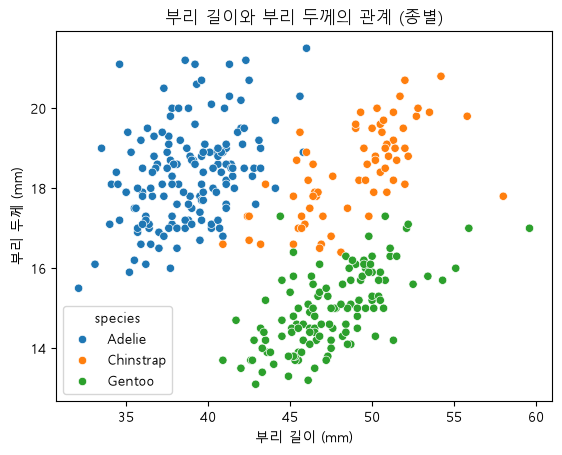

In [5]:
# 문제 1 · Q2

sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', hue='species')
plt.title('부리 길이와 부리 두께의 관계 (종별)')
plt.xlabel('부리 길이 (mm)')
plt.ylabel('부리 두께 (mm)')
plt.show()

### Q3 · 상관계수를 '전체'와 '종별'로 각각 구해 비교해 봅시다

- 두 변수의 상관계수를 **전체 데이터**에 대해 계산하세요.

- 같은 상관계수를 **종별로 나누어** 계산하세요.

- 두 결과의 **부호**를 비교하세요.

- `💡 힌트` 전체는 `df[['A','B']].dropna().corr()`,
  종별은 `df.groupby('species')[['A','B']].corr()`를 활용해 보세요.

In [6]:
# 문제 1 · Q3

cols = ['bill_length_mm', 'bill_depth_mm']
print("전체 상관계수:")
print(penguins[cols].dropna().corr())
print("\n종별 상관계수:")
print(penguins.groupby('species')[cols].corr())

전체 상관계수:
                bill_length_mm  bill_depth_mm
bill_length_mm        1.000000      -0.235053
bill_depth_mm        -0.235053       1.000000

종별 상관계수:
                          bill_length_mm  bill_depth_mm
species                                                
Adelie    bill_length_mm        1.000000       0.391492
          bill_depth_mm         0.391492       1.000000
Chinstrap bill_length_mm        1.000000       0.653536
          bill_depth_mm         0.653536       1.000000
Gentoo    bill_length_mm        1.000000       0.643384
          bill_depth_mm         0.643384       1.000000


### 💬 정리 · 결과를 말로 설명해 보기

- Q1의 산점도에서 두 변수는 어떤 방향의 관계로 보였나요? Q3의 전체 상관계수와 부호가 일치하나요?

- Q3의 종별 상관계수는 전체와 부호가 같나요, 다른가요?

- **같은 데이터인데 전체와 집단별 결론이 정반대로 나온 이유**를 설명해 보세요. 무엇이 이 착시를 만들고 있나요?

- 만약 이 데이터에 '종' 정보가 없었다면 우리는 어떤 잘못된 결론을 내렸을까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 부호가 뒤집히는 열쇠는 **종마다 부리의 '기본 크기'가 다르다**는 데 있습니다. 종별 평균이 어디에 놓여 있는지를 Q2의 그림에서 확인해 보세요.

- "전체를 보면 음, 나누면 양"은 두 변수 사이에 **숨은 집단 변수**가 끼어 있을 때 나타납니다. 이 현상에는 이름이 붙어 있고, 다음 시간 인과추론에서 다시 만납니다.

- 결론의 형태를 이렇게 나눠 써 보면 정확해집니다 — "종을 무시하면 ○○, 종을 고려하면 ○○".

</details>

In [8]:
# 문제 1 · 정리

# - Q1 그림은 약한 음의 관계처럼 보이고, 전체 상관계수 −0.235와 부호가 같습니다.
# - 종별로 나누면 세 종 모두 양수라서 부호가 반대입니다.
# - 이유는 종마다 부리의 기본 크기가 다르기 때문입니다. Gentoo는 부리가 길지만 얇고, Adelie는 짧지만 두껍습니다. 세 종을 한데 섞으면 종과 종 사이의 차이가 음의 기울기를 만들어 내고, 각 종 안의 양의 관계를 덮어 버립니다. 이 현상을 심슨의 역설이라고 하고, 여기서 species가 교란변수입니다.
# - 종 정보가 없었다면 "부리가 길수록 얇다"라는 잘못된 결론을 냈을 것입니다. 결론은 이렇게 쓸 수 있습니다: 종을 무시하면 음의 관계, 종을 고려하면 양의 관계.

## 문제 2 · 날개가 길면 몸무게도 무거울까? — 관계를 숫자로

`난이도 하` · `예상 20분`

**📖 상황**

- 문제 1에서 "숫자 전에 그림"을 배웠습니다. 이제 관계를 **숫자 하나**로 요약해 봅니다.

- 이번에는 **날개 길이(`flipper_length_mm`)와 몸무게(`body_mass_g`)**를 봅니다.
  이 두 변수는 **문제 5까지 계속 사용**하며, 상관 → 회귀 → 검정 → 진단으로 이어집니다.

- **피어슨 상관계수(r)**는 관계의 방향(부호)과 강도(절대값)를 −1~+1로 나타냅니다.
  다만 피어슨은 **두 변수가 정규분포라는 전제**에 기대는 모수적 방법입니다.

**🎯 이 문제로 배우는 것**

- 정규성 점검 → 피어슨(r과 p-값) → 스피어만 비교의 순서로, **강의에서 배운 절차 그대로** 상관을 구합니다.

결측치 제거 전: 344 행
결측치 제거 후: 342 행


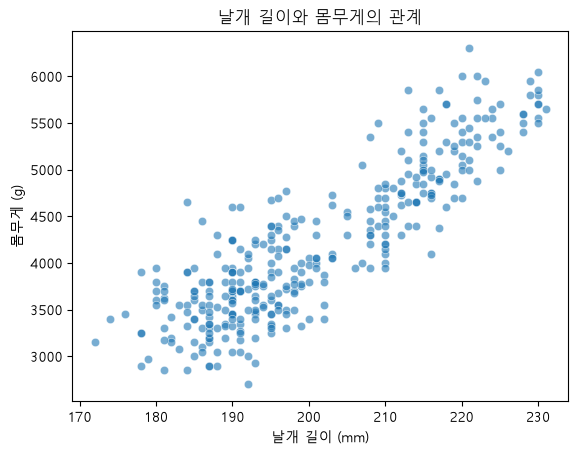

In [7]:
# 문제 2 · 데이터 준비 — 실행만 하세요
df_corr = penguins[['flipper_length_mm', 'body_mass_g']].dropna()

print("결측치 제거 전:", len(penguins), "행")
print("결측치 제거 후:", len(df_corr), "행")

# 두 변수의 관계를 그림으로 먼저 확인 (문제 1의 교훈!)
sns.scatterplot(data=df_corr, x='flipper_length_mm', y='body_mass_g', alpha=0.6)
plt.title("날개 길이와 몸무게의 관계")
plt.xlabel("날개 길이 (mm)")
plt.ylabel("몸무게 (g)")
plt.show()

### Q1 · 피어슨의 전제인 정규성을 점검해 봅시다

- `flipper_length_mm`과 `body_mass_g` **각각**에 대해 정규성 검정(Shapiro-Wilk)을 수행하세요.

- 유의수준 0.05를 기준으로 '정규성을 기각하는지'까지 함께 출력하세요.

- `💡 힌트` `stats.shapiro(데이터)`는 통계량과 p-값을 함께 돌려줍니다.

In [34]:
# 문제 2 · Q1

alpha = 0.05
for col in ['flipper_length_mm', 'body_mass_g']:
    stat, p = stats.shapiro(df_corr[col])
    result = "정규성 기각" if p < alpha else "정규성 기각 못함"
    print(f"{col}: W = {stat:.4f}, p = {p:.2e} → {result}")

flipper_length_mm: W = 0.9515, p = 3.54e-09 → 정규성 기각
body_mass_g: W = 0.9592, p = 3.68e-08 → 정규성 기각


### Q2 · 피어슨 상관계수와 p-값을 함께 구해 봅시다

- 상관계수만이 아니라 **p-값도 함께** 구하세요. 상관계수도 가설검정의 대상입니다.

- 결과는 반드시 `r`, `p_value`라는 이름으로 저장하세요. **문제 3·4에서 이어서 사용합니다.**

- `💡 힌트` `r, p_value = stats.pearsonr(x, y)` — 귀무가설은 "모집단의 상관계수가 0이다"입니다.

In [10]:
# 문제 2 · Q2

r, p_value = stats.pearsonr(df_corr['flipper_length_mm'], df_corr['body_mass_g'])
print(f"피어슨 r = {r:.4f}, p-value = {p_value:.2e}")

피어슨 r = 0.8712, p-value = 4.37e-107


### Q3 · 스피어만 상관계수를 구해 피어슨과 비교해 봅시다

- 스피어만 상관계수(ρ)를 구하세요.

- Q2의 피어슨 값과 **나란히 출력**해 두 값의 차이를 눈으로 확인하세요.

- `💡 힌트` `stats.spearmanr(x, y)`

In [35]:
# 문제 2 · Q3

rho, p_s = stats.spearmanr(df_corr['flipper_length_mm'], df_corr['body_mass_g'])
print(f"피어슨  r = {r:.4f} (p = {p_value:.2e})")
print(f"스피어만 ρ = {rho:.4f} (p = {p_s:.2e})")

피어슨  r = 0.8712 (p = 4.37e-107)
스피어만 ρ = 0.8400 (p = 2.76e-92)


### Q4 · 세 결과를 종합해 관계를 문장으로 정리해 봅시다

- Q1~Q3의 결과를 근거로, 오른쪽 빈칸을 채워 관계를 정리하세요.

- 숫자만 적지 말고 **그 숫자가 뜻하는 바**를 함께 쓰세요.

In [ ]:
# 문제 2 · Q4

# - 정규성 검정: 두 변수 모두 기각되어 피어슨의 전제가 엄밀하게는 지켜지지 않았습니다.
# - 피어슨 r = 0.871, p ≈ 4.4e-107로 유의합니다.
# - 스피어만 ρ = 0.840입니다.
# - 부호가 +이므로 날개가 길수록 몸무게도 무거운 양의 관계입니다.
# - 절대값이 0.84~0.87이라 매우 강한 관계입니다.

### 💬 정리 · 결과를 말로 설명해 보기

- Q1에서 정규성이 기각되었습니다. 그렇다면 피어슨 상관계수를 쓰면 안 되는 걸까요? Q2와 Q3의 값을 비교해서 판단해 보세요.

- 피어슨과 스피어만이 비슷하게 나왔다는 것은 무엇을 뜻할까요? 만약 두 값이 크게 달랐다면 어떤 상황을 의심해야 할까요?

- Q2의 p-값은 무엇에 대한 검정인가요? "상관계수가 크다"와 "상관계수가 유의하다"는 같은 말인가요?

- '날개가 길어지는 것이 몸무게를 무겁게 만드는 **원인**이다'라고 결론 내릴 수 있을까요? **교란변수 / 역인과 / 우연** 세 가지로 나누어 설명해 보세요.

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 정규성이 깨졌을 때 확인할 것은 "쓰면 안 되나"가 아니라 **"결론이 바뀌는가"**입니다. 두 계수가 거의 같다면 전제 위배의 영향이 작다는 뜻이고, 크게 다르면 이상치나 비선형을 의심합니다.

- p-값은 관계의 **크기**가 아니라 **존재**에 대한 답입니다. 표본이 커지면 아주 작은 상관도 유의해집니다 — 두 질문을 분리해서 답해 보세요.

- 인과를 부정하는 세 갈래를 이 데이터에 대입해 보세요. 교란변수 후보는 문제 1에서 이미 만났습니다.

</details>

In [ ]:
# 문제 2 · 정리

# - 정규성이 깨졌어도 피어슨과 스피어만 값이 거의 같아서 결론은 바뀌지 않습니다. 전제 위배의 영향이 작다고 볼 수 있습니다. 두 값이 크게 달랐다면 이상치나 비선형(단조이지만 곡선인) 관계를 의심해야 합니다.
# - p-값은 "모집단 상관계수가 0이다"를 검정한 결과입니다. 관계가 존재하는지에 대한 답이지 얼마나 큰지에 대한 답이 아닙니다. 표본이 크면 작은 r도 유의하게 나오므로 "크다"와 "유의하다"는 다른 말입니다.
# - 인과관계라고 결론 내릴 수는 없습니다.
#   - 교란변수: 종이나 성별이 날개와 몸무게를 함께 키울 수 있습니다. Gentoo는 둘 다 큽니다.
#   - 역인과: 몸이 무거워서 날개가 길게 발달했을 수도 있습니다.
#   - 우연: p가 극히 작아서 가능성은 낮지만 0은 아닙니다.

# 📌 상관계수와 상관 검정 정리 : 피어슨 vs 스피어만

---

## 1. 피어슨 상관계수 (Pearson r)

### 1-1. 정의

> **두 변수의 직선 관계 강도**를 −1 ~ 1로 나타낸 값 = 공분산에서 단위를 없앤 것

$$r = \frac{\text{Cov}(x, y)}{s_x \, s_y} = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2} \sqrt{\sum (y_i - \bar{y})^2}}$$

| r | 의미 |
|---|---|
| +1 | 완벽한 우상향 직선 |
| 0 | 직선 관계 없음 |
| −1 | 완벽한 우하향 직선 |

### 1-2. 검정

| 항목 | 내용 |
|---|---|
| 재는 것 | **직선 관계**의 강도 |
| 가정 | 두 변수가 **(이변량) 정규분포** |
| H₀ | 모집단 상관계수 ρ = 0 (정규분포에서는 = 두 변수가 독립) |

**원리**

1. 독립인 두 정규 주머니에서 n쌍을 뽑아 r을 구하는 일을 무한히 반복하면 → **0을 중심으로 한 r의 분포**가 생긴다
2. 정규성 덕분에 이 분포를 수학으로 정확히 안다 → r을 t로 바꾸면 **t(n−2) 분포**

$$t = \frac{r\sqrt{n-2}}{\sqrt{1 - r^2}}$$

3. 내 t가 이 분포에서 얼마나 극단적인지 = **p-값**

> - t = 신호(r) ÷ r의 표준오차
> - 순서를 지키는 변환이라 **r로 보나 t로 보나 p-값은 같다**
> - 단순회귀의 기울기 검정과 **같은 검정** (t, p 동일)

---

## 2. 스피어만 상관계수 (Spearman ρ)

### 2-1. 정의

> 값 대신 **"순위"**로 계산한 피어슨 상관계수
> 각 변수의 값을 크기 순서(1등, 2등, …)로 바꾼 뒤, 순위끼리 피어슨 r을 구한 것

### 2-2. 계산 예시

| 학생 | 공부시간 x | 점수 y | x 순위 | y 순위 | 순위 차이 d | d² |
|---|---|---|---|---|---|---|
| A | 1 | 10 | 1 | 1 | 0 | 0 |
| B | 2 | 30 | 2 | 3 | −1 | 1 |
| C | 3 | 20 | 3 | 2 | 1 | 1 |
| D | 4 | 50 | 4 | 5 | −1 | 1 |
| E | 5 | 40 | 5 | 4 | 1 | 1 |
| | | | | | **합** | **4** |

동점이 없을 때 쓰는 간단한 공식 (d : 두 순위의 차이)

$$\rho = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)}$$

$$\rho = 1 - \frac{6 \times 4}{5 \times 24} = 1 - 0.2 = 0.8$$

- 순위끼리 피어슨 r을 계산해도 똑같이 **0.8**
- 순위가 완전히 같으면 d = 0 → **ρ = 1** / 완전히 반대면 → **ρ = −1**

### 2-3. 검정

| 항목 | 내용 |
|---|---|
| 재는 것 | **단조 관계** (한 방향으로 함께 움직이는지) |
| 가정 | 정규성 **필요 없음** (비모수) |
| H₀ | 모집단 순위상관 = 0 (두 변수가 독립) |

**원리**

1. 값을 **순위(1, 2, …, n)**로 바꿔 ρ를 계산
2. H₀(독립)라면 y 순위가 x 순위와 **아무렇게나 짝지어진 것** → 가능한 모든 순위 배열이 똑같이 나올 수 있다
3. 그 모든 배열에서 ρ를 구한 분포에서 내 ρ가 얼마나 극단적인지 = **p-값**
   - n이 작으면 : 배열을 다 세서 정확히 계산
   - n이 크면 : 피어슨과 같은 t 변환으로 근사

$$t = \frac{\rho\sqrt{n-2}}{\sqrt{1 - \rho^2}}$$

> 원래 분포가 무엇이든 순위는 항상 1 ~ n 이라 **기준 분포가 데이터 모양에 의존하지 않는다** → 정규성이 필요 없는 이유

---

## 3. 피어슨 vs 스피어만

### 3-1. 핵심 차이 : 직선 vs 단조

> 피어슨은 **"직선"**을, 스피어만은 **"같은 방향으로 가는지(단조성)"**를 본다.

예 : x = (1, 2, 3, 4, 5), y = (2, 3, 5, 8, 50)

| | 값 | 이유 |
|---|---|---|
| 피어슨 r | 0.78 | 마지막 값이 직선에서 크게 벗어남 → 점수 깎음 |
| 스피어만 ρ | **1.00** | 순위만 보면 1등~5등 순서가 완벽히 같음 |

### 3-2. 상황별 비교

| 상황 | 피어슨 | 스피어만 |
|---|---|---|
| 곡선이지만 한 방향으로 증가·감소 | 과소평가 | 잘 잡음 |
| 이상치가 있음 | 크게 흔들림 | 덜 흔들림 (아무리 튀어도 순위는 1등일 뿐) |
| 정규분포가 아님 | 검정의 전제 위배 | 정규성 필요 없음 |
| 순서형 데이터 (만족도 1~5점, 등수) | 애매함 | 원래 순위라 잘 맞음 |
| 진짜 직선 + 정규분포 | **더 정확** | 순위로 바꾸며 정보 손실 |
| U자처럼 방향이 바뀌는 관계 | 못 잡음 (≈ 0) | 못 잡음 (≈ 0) |

### 3-3. 한눈에 비교

| | 피어슨 | 스피어만 |
|---|---|---|
| 계산 재료 | 원래 값 | 순위 |
| 관계 | 직선 | 단조 (곡선도 OK) |
| 가정 | 이변량 정규분포 | 없음 (비모수) |
| 기준 분포를 아는 방법 | 정규성 가정 → t(n−2) | 순위 배열의 경우의 수 |
| 이상치 | 민감 | 강함 |
| 회귀와의 연결 | 기울기 검정과 동일 | 직접 연결 없음 |
| 코드 | `stats.pearsonr(x, y)` | `stats.spearmanr(x, y)` |

> 덤 : 순위 기반 상관에는 **켄달 τ** 도 있다. 점 두 개씩 짝지어 "x가 큰 쪽이 y도 큰가?"를 센다. 표본이 작거나 동점이 많을 때 사용 → `stats.kendalltau(x, y)`

---

## 4. 실제로는 이렇게 쓴다 (문제 2의 흐름)

1. **산점도**부터 그린다 → 직선인지, 곡선인지, 이상치가 있는지
2. **정규성 검정** (Shapiro-Wilk) → 피어슨 검정의 전제 점검
3. **피어슨 r과 p-값**
4. **스피어만 ρ로 교차 확인** → 두 값을 비교

펭귄 (날개 길이 ↔ 몸무게) 결과 : 정규성 **기각**, 피어슨 r = **0.871**, 스피어만 ρ = **0.840**
→ 두 값이 비슷 = 정규성 위배가 결론에 큰 영향을 주지 않는다

| 두 값의 관계 | 의심할 것 |
|---|---|
| 비슷함 | 전제 위배 영향 작음 → 결론 유지 |
| 스피어만 ≫ 피어슨 | 단조 **곡선** 관계 |
| 피어슨 ≫ 스피어만 | **이상치** 몇 개가 r을 끌어올림 |

---

## 🧭 한 문장 정리

> - **피어슨** : 원래 값으로 **직선 관계**를 재고, 정규성 가정 아래 t(n−2) 분포로 "독립이라면 얼마나 희귀한가"를 판단한다.
> - **스피어만** : 순위로 바꿔 **단조 관계**를 재고, 순위 배열의 경우의 수로 판단하므로 **정규성이 필요 없고 이상치에 강하다.**

### 💡 왜 t(n−2) 분포를 따르나? : 기하학적 유도

> **핵심** : r 은 두 벡터 사이 각도의 **cos** 이다 → r/√(1−r²) 는 **cot** → 이것이 "정규 ÷ √(카이제곱/자유도)" 꼴이 된다

---

#### ① r = 두 벡터의 cos θ

평균을 뺀 벡터를 $\mathbf{x} = (x_i - \bar x)$, $\mathbf{y} = (y_i - \bar y)$ 라 하면

$$r = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum (x_i-\bar x)^2}\sqrt{\sum (y_i-\bar y)^2}} = \frac{\mathbf{x}\cdot\mathbf{y}}{|\mathbf{x}||\mathbf{y}|} = \cos\theta$$

> 평균을 빼면 자유도가 1 줄어 → 두 벡터는 사실상 **(n−1)차원** 공간에 있다

---

#### ② y 를 "x 방향 성분"과 "나머지"로 쪼개기

x 방향 단위벡터 $\mathbf{u} = \mathbf{x}/|\mathbf{x}|$ 에 대해

$$Z = \mathbf{y}\cdot\mathbf{u} \quad(\text{x 방향 성분}), \qquad |\mathbf{y}|^2 = Z^2 + |\mathbf{W}|^2 \quad(\mathbf{W} : \text{수직인 } (n-2)\text{차원 나머지})$$

$$r = \frac{Z}{\sqrt{Z^2 + |\mathbf{W}|^2}}$$

---

#### ③ r 을 t 모양으로 바꾸기

$$1 - r^2 = \frac{|\mathbf{W}|^2}{Z^2 + |\mathbf{W}|^2} \quad\Rightarrow\quad \frac{r}{\sqrt{1-r^2}} = \frac{Z}{|\mathbf{W}|}$$

양변에 √(n−2) 를 곱하면

$$t = \frac{r\sqrt{n-2}}{\sqrt{1-r^2}} = \frac{Z}{\sqrt{|\mathbf{W}|^2/(n-2)}}$$

---

#### ④ 왜 정확히 t(n−2) 인가 (H₀ : 독립, y 정규)

| 성분 | 분포 | 이유 |
|---|---|---|
| Z | N(0, σ²) | y 는 모든 방향으로 똑같이 퍼진 정규분포(구형 대칭) → x 가 어느 방향이든 무관 |
| \|W\|² / σ² | χ²(n−2) | 나머지 n−2 개 직교 방향 성분도 각각 N(0, σ²) |
| Z 와 W | **독립** | 서로 직교하는 정규 성분 |

$$t = \frac{Z/\sigma}{\sqrt{\chi^2_{n-2}/(n-2)}} \sim t(n-2) \qquad (\sigma \text{ 는 약분되어 사라짐})$$

---

#### ⑤ 2번 표와 연결

| 노트북 표현 | 기하학적 의미 |
|---|---|
| r (신호) | y 중 **x 방향으로 정렬된** 부분 Z |
| √(1 − r²) (잡음) | x 와 **무관한 방향**으로 흩어진 부분 \|W\| |
| √(n − 2) (증거의 양) | 잡음이 퍼진 **차원 수**로 나눠 1차원당 평균을 냄 |
| n − 2 인 이유 | 평균 빼기(−1) + x 방향(−1) |

> - **정규성은 사실 y 쪽만 필요** : x 를 고정해도 성립 → 회귀의 "오차는 정규분포" 가정과 같은 조건
> - **ρ ≠ 0 이면 성립하지 않음** : y 가 x 방향으로 치우쳐 Z 의 평균이 0 이 아님 → **Fisher z 변환** $z = \tfrac{1}{2}\ln\tfrac{1+r}{1-r}$ 사용
> - 거꾸로 풀면 H₀ 에서 r 의 밀도는 $f(r) \propto (1-r^2)^{(n-4)/2}$ → 1번의 "0 중심으로 흩어진 r 의 분포"가 이것이고, n 이 클수록 0 근처로 좁아진다

## 문제 3 · 그 관계를 하나의 식으로 만들 수 있을까?

`난이도 중` · `예상 25분`

**📖 상황**

- 상관계수는 "관계가 얼마나 **강한가**"만 알려주고, "날개가 1mm 길면 몸무게가 **몇 g** 늘어나는가"는
  말해주지 않습니다. 그 답을 주는 것이 **선형회귀(Linear Regression)**입니다.

- 흩어진 점들을 가장 잘 가로지르는 직선 `y = a + bx`를 찾아 관계를 하나의 **식**으로 표현합니다.
  `a`(절편)는 x가 0일 때의 예측값, `b`(기울기)는 **x가 1 늘 때 y가 평균적으로 변하는 양**입니다.

- 그런데 상관과 회귀는 **서로 남이 아닙니다.** 문제 2에서 구한 `r`과
  이번에 구할 기울기·결정계수 사이에는 정확한 관계식이 성립합니다.

**🎯 이 문제로 배우는 것**

- 회귀식을 적합·해석하고, **상관과 회귀가 한 뿌리임을 숫자로 확인**합니다.

In [36]:
# 문제 3 · 데이터 준비 — 실행만 하세요
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])

print("분석에 사용할 데이터:", len(penguins_cleaned), "행")
print("문제 2의 df_corr과 동일한가?:", len(penguins_cleaned) == len(df_corr))

분석에 사용할 데이터: 342 행
문제 2의 df_corr과 동일한가?: True


### Q1 · 단순회귀 모델을 적합해 봅시다

- **날개 길이(설명변수) → 몸무게(반응변수)** 회귀 모델을 적합하세요.

- 적합한 모델은 반드시 `model`이라는 이름으로 저장하세요. **문제 4·5에서 이어서 사용합니다.**

- `💡 힌트` `model = smf.ols(formula='body_mass_g ~ flipper_length_mm', data=...).fit()`

In [14]:
# 문제 3 · Q1

model = smf.ols(formula='body_mass_g ~ flipper_length_mm', data=penguins_cleaned).fit()

### Q2 · 분석 결과표를 출력해 봅시다

- 적합한 모델의 요약 결과표를 출력하세요.

- `coef`, `P>|t|`, `R-squared` 열이 각각 어디에 있는지 눈으로 찾아 두세요. 다음 문제들에서 계속 씁니다.

- `💡 힌트` 모델 객체의 `.summary()` 메소드를 사용하세요.

In [15]:
# 문제 3 · Q2

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     1071.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          4.37e-107
Time:                        12:03:55   Log-Likelihood:                -2528.4
No. Observations:                 342   AIC:                             5061.
Df Residuals:                     340   BIC:                             5069.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -5780.8314    305.81

### Q3 · 회귀식을 완성해 봅시다

- Q2의 결과표에서 **절편**과 **기울기**를 찾아 오른쪽 빈칸을 채우세요.

- 숫자를 옮겨 적은 뒤, 완성된 식을 한 줄로 써 보세요.

In [ ]:
# 문제 3 · Q3

# - 절편 a = −5780.83
# - 기울기 b = 49.69
# - 회귀식: 몸무게(g) = −5780.83 + 49.69 × 날개길이(mm)

### Q4 · 회귀식으로 예측해 봅시다

- 날개 길이가 평균보다 **10mm 더 긴** 펭귄은, 평균적인 펭귄보다 몸무게가 몇 g 더 무거울까요?

- 계산 결과를 단위(g)와 함께 출력하세요.

- `💡 힌트` 기울기 × 10

In [16]:
# 문제 3 · Q4

diff = model.params['flipper_length_mm'] * 10
print(f"날개가 10mm 더 길면 몸무게가 평균 {diff:.1f} g 더 무겁다")

날개가 10mm 더 길면 몸무게가 평균 496.9 g 더 무겁다


### Q5 · 상관과 회귀를 잇는 두 관계식을 확인해 봅시다

- 다음 두 식이 실제로 성립하는지 **숫자로** 확인하세요.
  - ① 기울기 = `r` × (y의 표준편차 / x의 표준편차)
  - ② 결정계수 `R²` = `r²` _(단순회귀에서만 성립)_

- 좌변과 우변을 **나란히 출력**해 두 값이 일치하는지 눈으로 확인하세요.

- `💡 힌트` 문제 2 Q2의 `r`을 사용합니다. 표준편차는 `.std(ddof=1)`, 모델의 R²는 `model.rsquared`입니다.

In [17]:
# 문제 3 · Q5

x = penguins_cleaned['flipper_length_mm']
y = penguins_cleaned['body_mass_g']
slope_calc = r * (y.std(ddof=1) / x.std(ddof=1))
print(f"① 기울기: 모델 = {model.params['flipper_length_mm']:.4f} | r×(sy/sx) = {slope_calc:.4f}")
print(f"② R²: 모델 = {model.rsquared:.4f} | r² = {r**2:.4f}")

① 기울기: 모델 = 49.6856 | r×(sy/sx) = 49.6856
② R²: 모델 = 0.7590 | r² = 0.7590


## 📌 상관과 회귀를 잇는 두 관계식

---

### 📖 용어 정리

**편차** : 각 값이 평균에서 떨어진 정도 → x_i − x̄ , y_i − ȳ

| 기호 | 이름 | 정의 | 의미 |
|---|---|---|---|
| S_xx | x의 제곱합 | Σ(x_i − x̄)² | x 편차를 제곱해 **다 더한 것** |
| S_yy | y의 제곱합 | Σ(y_i − ȳ)² | y 편차를 제곱해 다 더한 것 |
| S_xy | 교차곱합 | Σ(x_i − x̄)(y_i − ȳ) | x 편차 × y 편차를 다 더한 것 |
| Var(x) = σ_x² | 분산 | S_xx / n | 제곱합의 **평균** (퍼진 정도) |
| σ_x | 표준편차 | √(S_xx / n) | 분산의 루트 (원래 단위로 되돌림) |
| Cov(x, y) | 공분산 | S_xy / n | 교차곱합의 평균 (함께 움직이는 정도) |
| r | 상관계수 | Cov(x, y) / (σ_x σ_y) | 공분산에서 단위를 없앤 것 (−1 ~ 1) |

> ⚠️ σ_x 는 "제곱합의 루트(√S_xx)"가 아니라 **"제곱합을 n으로 나눈 뒤 루트"**다.
> 표본에서는 n 대신 **n − 1** 로 나누기도 한다(`.std(ddof=1)`). 아래 식들에서는 분자·분모에 같은 n이 들어가 **약분되므로 어느 쪽이든 결과가 같다.**

**회귀 관련 기호**

| 기호 | 이름 | 정의 |
|---|---|---|
| β₀ , β₁ | 절편 , 기울기 | 회귀선 ŷ = β₀ + β₁x |
| ŷ_i | 예측값 | β₀ + β₁x_i |
| y_i − ŷ_i | 잔차 | 실제값 − 예측값 |
| SSE | 잔차제곱합 | Σ(y_i − ŷ_i)² → 회귀로 **설명 못 한** 변동 |
| ESS | 회귀제곱합 | Σ(ŷ_i − ȳ)² → 회귀로 **설명된** 변동 |
| TSS | 총제곱합 | Σ(y_i − ȳ)² = S_yy → y의 **전체** 변동 (TSS = ESS + SSE) |

---

### ⓪ 출발점 · 최소제곱법(OLS)으로 회귀선 구하기

회귀선 ŷ = β₀ + β₁x 는 **잔차제곱합(SSE)이 가장 작아지는** β₀, β₁ 으로 정한다.

$$SSE = \sum (y_i - \beta_0 - \beta_1 x_i)^2$$

> 잔차를 그냥 더하면 +, − 가 상쇄되므로 **제곱해서 더한다** → "최소**제곱**법"

**(1) β₀ 로 미분 → 0**

$$\sum (y_i - \beta_0 - \beta_1 x_i) = 0 \quad \Rightarrow \quad \beta_0 = \bar{y} - \beta_1 \bar{x}$$

→ 회귀선은 항상 **평균점 (x̄, ȳ)** 을 지난다

**(2) β₀ 를 대입해 SSE 를 다시 쓰기**

$$SSE = \sum \left[ (y_i - \bar{y}) - \beta_1 (x_i - \bar{x}) \right]^2$$

**(3) β₁ 로 미분 → 0**

$$\sum (x_i - \bar{x}) \left[ (y_i - \bar{y}) - \beta_1 (x_i - \bar{x}) \right] = 0$$

$$\sum (x_i - \bar{x})(y_i - \bar{y}) = \beta_1 \sum (x_i - \bar{x})^2$$

$$\beta_1 = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sum (x_i - \bar{x})^2} = \frac{S_{xy}}{S_{xx}}$$

> 이 β₁ 이 아래 ①, ② 의 출발점이다.

---

### ① 기울기 = r × (σ_y / σ_x)

**(1) ⓪에서 구한 기울기를 공분산·분산으로 표현**

분자·분모를 각각 n으로 나누면

$$\beta_1 = \frac{S_{xy}}{S_{xx}} = \frac{S_{xy} / n}{S_{xx} / n} = \frac{\text{Cov}(x, y)}{\text{Var}(x)} = \frac{\text{Cov}(x, y)}{\sigma_x^2}$$

**(2) 상관계수의 정의를 이용**

$$r = \frac{\text{Cov}(x, y)}{\sigma_x \sigma_y} \quad \Rightarrow \quad \text{Cov}(x, y) = r \sigma_x \sigma_y$$

**(3) 대입**

$$\beta_1 = \frac{r \sigma_x \sigma_y}{\sigma_x^2} = r \cdot \frac{\sigma_y}{\sigma_x}$$

> **의미**
> - 기울기는 상관계수에 두 변수의 **표준편차 비를 곱해 단위를 맞춘 값**이다.
> - x와 y를 각각 표준화하면 σ_y / σ_x = 1 → **기울기 = r**

---

### ② R² = r² (단순회귀에서만)

**(1) R²의 정의** : y의 변동 중 회귀선이 설명하는 비율

$$R^2 = \frac{ESS}{TSS} = \frac{\sum (\hat{y}_i - \bar{y})^2}{\sum (y_i - \bar{y})^2}$$

**(2) 분자(ESS) 정리**

⓪에서 회귀선이 평균점을 지나므로 (β₀ = ȳ − β₁x̄)

$$\hat{y}_i - \bar{y} = \beta_1 (x_i - \bar{x})$$

$$ESS = \beta_1^2 \sum (x_i - \bar{x})^2 = \beta_1^2 S_{xx}$$

**(3) ①의 β₁ 대입**

분자·분모를 n으로 나누면 S_xx 는 σ_x², S_yy 는 σ_y² 가 된다.

$$R^2 = \frac{\beta_1^2 S_{xx}}{S_{yy}} = \frac{\beta_1^2 \sigma_x^2}{\sigma_y^2} = r^2 \cdot \frac{\sigma_y^2}{\sigma_x^2} \cdot \frac{\sigma_x^2}{\sigma_y^2} = r^2$$

> **왜 단순회귀에서만?**
> - 설명변수가 하나일 때만 ŷ 가 **x의 선형함수 하나뿐**이라 깔끔하게 떨어진다.
> - 변수가 둘 이상이면 R² 는 **y와 ŷ 의 상관계수 제곱**이 되어, 개별 변수의 r² 와는 일반적으로 다르다.

$$R^2 = r_{y, \hat{y}}^2$$

---

### ✅ 펭귄 데이터로 확인 (날개 길이 → 몸무게, r = 0.8712)

| 관계식 | 좌변 (모델 출력) | 우변 (r로 계산) |
|---|---|---|
| ① 기울기 | `model.params` = 49.69 | r × (s_y / s_x) = 49.69 |
| ② 결정계수 | `model.rsquared` = 0.759 | r² = 0.8712² = 0.759 |

---

### 🧭 한 문장 정리

> 최소제곱법으로 구한 단순회귀의 기울기는 **r에 단위를 입힌 것**이고, 설명력 R²는 **r을 제곱한 것**이다. 그래서 상관과 단순회귀는 같은 관계를 다른 방식으로 표현한 것이다.

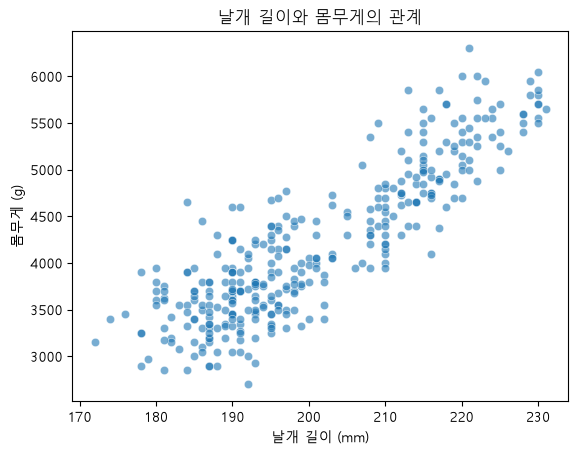

In [40]:
# 두 변수의 관계
sns.scatterplot(data=df_corr, x='flipper_length_mm', y='body_mass_g', alpha=0.6)
plt.title("날개 길이와 몸무게의 관계")
plt.xlabel("날개 길이 (mm)")
plt.ylabel("몸무게 (g)")
plt.show()

### 💬 정리 · 결과를 말로 설명해 보기

- 기울기(b) 값을 "날개 길이가 ○○할 때 몸무게가 ○○한다"는 문장으로 풀어 써 보세요.

- 절편(a)이 음수로 나왔습니다. 이 숫자를 "날개 길이가 0mm인 펭귄의 몸무게"로 해석해도 될까요? 왜 그럴까요?

- Q5에서 `R² = r²`을 확인했습니다. 그렇다면 설명변수와 반응변수를 서로 바꿔 분석하면 **기울기**와 **R²**는 각각 같을까요, 다를까요?

- 상관계수 `r`은 단위 없는 −1~1 값이고, 기울기 `b`는 'mm당 g'이라는 단위를 가집니다. 회귀가 상관보다 더 알려주는 것은 무엇인가요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 절편은 **데이터가 존재하는 범위 밖의 값**입니다. 날개 길이 0mm인 펭귄은 우리 데이터에 없습니다 — 회귀식은 관측 범위 안에서만 의미를 갖습니다.

- x와 y를 바꿨을 때를 생각할 때 기준은 **"r은 대칭인가, s_y/s_x는 대칭인가"**입니다. 두 관계식 ①②를 각각 대입해 보면 답이 갈립니다.

- "강도"와 "변화량"의 차이로 정리해 보세요. 보고서에 "1mm당 ○g"을 쓸 수 있는 쪽은 어느 것인가요?

</details>

In [ ]:
# 문제 3 · 정리

# - 기울기 해석: 날개 길이가 1mm 길어질 때 몸무게는 평균 약 49.7g 늘어납니다.
# - 음수 절편을 "날개 0mm인 펭귄의 몸무게"로 해석하면 안 됩니다. 0mm는 데이터 범위(약 172~231mm) 밖이라서 직선을 범위 밖으로 연장한 값일 뿐입니다.
# - x와 y를 바꾸면 r은 대칭이라 R²는 같습니다. 하지만 s_y/s_x가 s_x/s_y로 바뀌므로 기울기는 달라집니다.
# - 상관은 관계의 강도만 알려 줍니다. 회귀는 "1mm당 약 50g"처럼 단위가 있는 변화량을 알려 주고, 그 식으로 예측도 할 수 있습니다.


## 문제 4 · 이 기울기, 우연이 아니라고 말할 수 있을까?

`난이도 중` · `예상 25분`

**📖 상황**

- 문제 3에서 기울기를 구했습니다. 그런데 이 값은 **표본 342마리에서 계산된 값**입니다.

- 만약 전체 펭귄 집단에서 두 변수가 실제로는 아무 관계가 없다면(**기울기 = 0**),
  우리가 얻은 기울기는 그저 **표본을 뽑는 과정에서 우연히 생긴 값**일 수도 있습니다.

- 이 의심에 답하는 것이 **회귀계수의 가설검정**이고, 결과표의 `P>|t|` 열이 판단 근거입니다.

**🎯 이 문제로 배우는 것**

- 강의에서 배운 **상관계수의 유의성 검정**과 회귀계수 검정이 **같은 검정**임을 확인하고,
  p-값이 항상 작게 나오는 것은 아니라는 사실을 **기각 실패 사례**로 직접 만납니다.

In [33]:
# 문제 4 · 데이터 준비

print("분석 대상 데이터:", len(penguins_cleaned), "행 (문제 3과 동일)")
print("설명변수: flipper_length_mm  /  반응변수: body_mass_g")

분석 대상 데이터: 342 행 (문제 3과 동일)
설명변수: flipper_length_mm  /  반응변수: body_mass_g


### Q1 · 가설을 세워 봅시다

- 회귀계수(기울기)에 대한 귀무가설(H₀)과 대립가설(H₁)을 오른쪽 빈칸에 쓰세요.

- '기울기'가 무엇과 같은지/다른지를 명확히 적으세요.

In [ ]:
# 문제 4 · Q1
# H₀ (귀무가설): 날개 길이의 회귀계수(기울기) = 0. 즉 날개 길이는 몸무게와 선형 관계가 없습니다.
# H₁ (대립가설): 기울기 ≠ 0

### Q2 · 기울기의 p-값을 찾아 봅시다

- `flipper_length_mm` 행에서 `P>|t|` 열의 값을 찾아 출력하세요.

- `💡 힌트` 결과표에서 눈으로 찾아도 되고, 모델 객체의 `.pvalues` 속성을 써도 됩니다.

In [18]:
# 문제 4 · Q2

p_slope = model.pvalues['flipper_length_mm']
print(f"기울기 p-value = {p_slope:.2e}")

기울기 p-value = 4.37e-107


### Q3 · 유의수준 0.05로 결론을 내려 봅시다

- p-값과 유의수준 `alpha = 0.05`를 비교해, **판정 결과를 문장으로 출력하는 코드**를 작성하세요.

- 숫자만 찍지 말고 "기각한다 / 기각하지 못한다"까지 출력되도록 만드세요.

In [19]:
# 문제 4 · Q3
alpha = 0.05
if p_slope < alpha:
    print(f"p = {p_slope:.2e} < {alpha} → 귀무가설을 기각한다. 기울기는 통계적으로 유의하다.")
else:
    print(f"p = {p_slope:.2e} ≥ {alpha} → 귀무가설을 기각하지 못한다.")

p = 4.37e-107 < 0.05 → 귀무가설을 기각한다. 기울기는 통계적으로 유의하다.


### Q4 · 상관계수의 검정과 같은 검정인지 확인해 봅시다

- 강의에서 배운 공식으로 t-통계량을 **직접 계산**하세요.

  `t = r × √(n − 2) / √(1 − r²)`

- 이 값을 `model.tvalues['flipper_length_mm']`와 **나란히 출력**해 비교하세요.

- `💡 힌트` `n`은 표본 크기(`len(penguins_cleaned)`), `r`은 문제 2 Q2에서 구한 값입니다.

In [20]:
# 문제 4 · Q4

n = len(penguins_cleaned)
t_calc = r * np.sqrt(n - 2) / np.sqrt(1 - r**2)
print(f"직접 계산 t = {t_calc:.4f} | 모델 t = {model.tvalues['flipper_length_mm']:.4f}")

직접 계산 t = 32.7222 | 모델 t = 32.7222


## 📌 상관계수 검정 = 단순회귀 기울기 검정

> **결론** : 단순회귀에서 기울기 검정과 상관계수 검정은 **같은 검정**이다. t 도 p 도 똑같이 나온다.

---

### 1. r 의 검정 : 직관

**질문** : 내가 얻은 r 이 "우연히 나온 값"일 수도 있지 않을까?

1. 두 변수가 **독립(H₀ : ρ = 0)**인 두 주머니가 있다고 하자
2. 각 주머니에서 n 개씩 짝지어 뽑아 r 을 계산한다
3. 이 일을 무한히 반복하면 → **0 을 중심으로 흩어진 r 의 분포**가 생긴다
4. 내 r 이 이 분포에서 **얼마나 바깥쪽(희귀한 쪽)**에 있는지 = **p-값**

> - 독립이어도 r 은 표본마다 0.05, −0.12, 0.08 … 처럼 우연히 흔들린다
> - n = 30 이면 95% 가 약 −0.36 ~ +0.36 사이 → 그 밖이면 "우연이라 보기 어렵다"
> - **표본이 클수록** 우연의 폭이 좁아진다 (n = 342 이면 약 ±0.11)

---

### 2. 이 분포를 t 분포로 나타내기

두 변수가 정규분포라면, r 을 아래처럼 바꾸면 **t(n−2) 분포**를 정확히 따른다.

$$t = \frac{r \sqrt{n-2}}{\sqrt{1 - r^2}}$$


| 부분 | 의미 |
|---|---|
| r | **신호** : 관계의 강도 |
| √(1 − r²) | **잡음** : 직선으로 설명 못 한 흩어짐 |
| √(n − 2) | **증거의 양** : 표본 크기 |

> - 즉 t = r ÷ (r 의 표준오차), 표준오차는 √((1 − r²) / (n − 2))
> - r 이 커지면 t 도 항상 커지는 **순서를 지키는 변환** → r 로 보나 t 로 보나 **p-값은 같다**

---

### 3. r 과 기울기 β 의 관계

r 과 b 는 **분자(공분산)가 같고, 분모만 다르다.**

$$r = \frac{\text{Cov}(x, y)}{s_x \, s_y} = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2} \sqrt{\sum (y_i - \bar{y})^2}}$$


$$ b = \frac{\text{Cov}(x, y)}{\sigma_x^2}$$

| | 분모 | 단위 |
|---|---|---|
| 공분산 Cov(x, y) | — | x 단위 × y 단위 (mm·g) |
| 상관계수 r | σ_x σ_y | x 단위 × y 단위 ÷ (x 단위 × y 단위) = **단위 없음** |
| 기울기 b | σ_x² | x 단위 × y 단위 ÷ (x 단위)² = **y 단위 / x 단위** (g/mm) |

> - r 의 분모 σ_x σ_y 가 공분산의 **단위를 지워** −1 ~ 1 로 만든다
> - b 의 분모 σ_x² 는 x 단위만 지워 **"x 1 단위당 y 변화량"**을 남긴다

Cov(x, y) = r σ_x σ_y 를 b 에 넣으면, 두 값은 서로 이렇게 오간다.

$$b = r \cdot \frac{\sigma_y}{\sigma_x} \qquad \Longleftrightarrow \qquad r = b \cdot \frac{\sigma_x}{\sigma_y}$$

| 방향 | 식 | 의미 |
|---|---|---|
| r → b | b = r × (σ_y / σ_x) | r 에 **단위를 입힌 것**이 기울기 |
| b → r | r = b × (σ_x / σ_y) | 기울기에서 **단위를 벗긴 것**이 r |

> - x, y 를 둘 다 표준화하면 σ_y / σ_x = 1 → **기울기 = r**
> - 펭귄 예 : r = 49.69 × (14.06 / 802.0) = **0.871** (g/mm 단위가 사라짐)

---

### 4. 그래서 검정도 같아진다 : 직관

- 기울기는 **r 에 단위(σ_y / σ_x)를 입힌 값**이다 → b = r · σ_y / σ_x
- 기울기의 표준오차 SE(b) 에도 **똑같은 단위**가 붙어 있다
- b ÷ SE(b) 로 나누는 순간 **단위가 상쇄** → r 만으로 계산한 t 와 같아진다

> 키를 cm 로 재든 인치로 재든 "누가 더 큰가"의 답은 같다.
> 단위만 바꾼다고 **"관계가 있는가"의 판단은 바뀌지 않는다.**

---

### 5. 기울기의 표준오차 SE(b) 구하기

> **SE(b) = √(σ̂² / S_xx)** : 잔차로 추정한 오차의 흩어짐(σ̂²)을 x 의 퍼진 정도(S_xx)로 나눈 것

**① b 의 분산** : b 는 y 들의 가중합

$$b = \sum c_i y_i, \quad c_i = \frac{x_i - \bar{x}}{S_{xx}}$$

$$\text{Var}(b) = \sigma^2 \sum c_i^2 = \frac{\sigma^2}{S_{xx}}$$

**② σ² 추정** : 진짜 오차는 모르므로 잔차로 대신

$$\hat{\sigma}^2 = \frac{SSE}{n - 2}$$

> n − 2 : b₀, b₁ 두 개를 추정하며 자유도 2개를 썼기 때문

**③ 대입 후 루트**

$$SE(b) = \sqrt{\frac{\hat{\sigma}^2}{S_{xx}}} = \sqrt{\frac{SSE}{(n-2) S_{xx}}}$$

**펭귄 확인**

| SSE | n − 2 | σ̂² | S_xx | **SE(b)** |
|---|---|---|---|---|
| 52,854,796 | 340 | 155,455 | 67,426.5 | **1.518** (`model.bse`와 동일) |

> 오차(σ̂²)가 작을수록, **x 가 넓게 퍼질수록(S_xx 가 클수록)** 기울기가 정확해진다

---

### 6. β 로 넣어도 같은 t 가 나온다 : 수식

회귀 기울기 검정의 t 는 (SE(b) 는 5번에서 구함)

$$t = \frac{b}{SE(b)}, \quad SE(b) = \sqrt{\frac{SSE}{(n-2) S_{xx}}}$$

여기에 r 로 표현한 두 식을 넣는다.

| 재료 | r 로 표현 | 출처 |
|---|---|---|
| 기울기 b | r √(S_yy / S_xx) | 3번 (σ_y / σ_x = √(S_yy / S_xx)) |
| 잔차제곱합 SSE | S_yy (1 − r²) | R² = r² 이므로 설명 못 한 비율이 1 − r² |

**분자** (단위 = √(S_yy / S_xx))

$$b = r \sqrt{\frac{S_{yy}}{S_{xx}}}$$

**분모** (여기에도 같은 단위 √(S_yy / S_xx) 가 붙어 있다)

$$SE(b) = \sqrt{\frac{S_{yy} (1 - r^2)}{(n-2) S_{xx}}} = \sqrt{\frac{S_{yy}}{S_{xx}}} \cdot \sqrt{\frac{1 - r^2}{n-2}}$$

**나누면 단위가 상쇄**

$$t = \frac{b}{SE(b)} = \frac{r}{\sqrt{\frac{1 - r^2}{n-2}}} = \frac{r \sqrt{n-2}}{\sqrt{1 - r^2}}$$

→ 2번의 **r 로 표현한 t 와 정확히 같다**
→ 자유도도 둘 다 **n − 2** → **p-값도 같다**

---

### 7. 숫자로 확인 (펭귄 : 날개 길이 → 몸무게, n = 342)

| 검정 | 계산 | t | p |
|---|---|---|---|
| 회귀 기울기 | b / SE(b) = 49.69 / 1.518 | **32.72** | 4.4e-107 |
| 상관계수 | 0.8712 × √340 / √(1 − 0.759) | **32.72** | 4.4e-107 |

```python
n = len(penguins_cleaned)
t_r = r * np.sqrt(n - 2) / np.sqrt(1 - r**2)                                # r 로 계산
t_b = model.params['flipper_length_mm'] / model.bse['flipper_length_mm']    # β 로 계산
print(f"r 로 계산한 t = {t_r:.4f}  |  β 로 계산한 t = {t_b:.4f}")
```

---

### ⚠️ 단순회귀에서만

- 설명변수가 하나일 때만 b 가 r 하나로 표현된다
- 다중회귀의 계수 검정은 단순 상관 r 이 아니라 **편상관**(다른 변수를 통제한 상관)의 검정과 같아진다

---

### 🧭 한 문장 정리

> r 의 검정은 "독립이라면 r 이 얼마나 희귀한가"를 t(n−2) 분포로 본 것이고,
> 기울기는 r 에 단위를 입힌 값이며 그 표준오차에도 같은 단위가 붙어 있어,
> **β 로 계산한 t 가 r 로 계산한 t 와 정확히 같아진다.**

### Q5 · p-값이 크게 나오는 사례를 만나 봅시다

- **Adelie 종 수컷만** 골라, `bill_length_mm`으로 `body_mass_g`를 설명하는 회귀를 적합하세요.

- 기울기의 p-값을 유의수준 0.05와 비교하고, 표본 크기(n)와 `R²`도 함께 출력하세요.

- `💡 힌트` 먼저 필요한 열의 결측치를 제거한 뒤 조건으로 걸러 냅니다.
  `df[(df['species'] == 'Adelie') & (df['sex'] == 'Male')]`

In [21]:
# 문제 4 · Q5

adelie = penguins.dropna(subset=['bill_length_mm', 'body_mass_g', 'sex'])
adelie_m = adelie[(adelie['species'] == 'Adelie') & (adelie['sex'] == 'Male')]
model_am = smf.ols('body_mass_g ~ bill_length_mm', data=adelie_m).fit()
p_am = model_am.pvalues['bill_length_mm']
print(f"n = {len(adelie_m)}, 기울기 = {model_am.params['bill_length_mm']:.2f}, "
      f"p = {p_am:.4f}, R² = {model_am.rsquared:.4f}")
print("귀무가설 기각" if p_am < 0.05 else "귀무가설 기각 못함")

n = 73, 기울기 = 33.56, p = 0.0610, R² = 0.0486
귀무가설 기각 못함


### 💬 정리 · 결과를 말로 설명해 보기

- p-값이 작다는 것은 정확히 무엇이 작다는 뜻인가요? "귀무가설이 참일 확률"이라고 말해도 될까요?

- Q4에서 두 t값이 일치했습니다. 이것은 상관계수의 검정과 회귀계수의 검정이 **어떤 관계**임을 뜻하나요?

- Q5의 결과는 Q2와 어떻게 달랐나요? 같은 `penguins` 데이터인데 결론이 갈린 이유를 **표본 크기**와 **관계의 강도(R²)** 두 측면에서 설명해 보세요.

- Q5처럼 p-값이 0.05보다 조금 큰 경우, "두 변수는 관계가 없음이 증명되었다"고 말할 수 있을까요? 어떻게 말하는 것이 정확할까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- p-값은 "H₀가 참이라고 **가정했을 때** 이런 결과가 나올 확률"입니다. 가정과 결론의 방향을 뒤집지 않도록 문장을 조심해서 써 보세요.

- Q4의 일치는 우연이 아닙니다. 단순회귀에서는 "두 변수가 무관하다"는 하나의 가설을 두 가지 방식으로 적었을 뿐입니다 — 그래서 t도 p도 같습니다.

- 기각 실패는 **"관계가 없다"가 아니라 "관계가 있다는 증거가 부족하다"**입니다. Q5의 n과 R²를 보면 왜 증거가 부족했는지 짐작할 수 있습니다.

</details>

In [23]:
# 문제 4 · 정리

# - p-값은 "H₀가 참이라고 가정했을 때 지금만큼 또는 더 극단적인 결과가 나올 확률"입니다. "H₀가 참일 확률"이 아닙니다.
# - 단순회귀에서는 상관계수 검정과 기울기 검정이 같은 가설("두 변수가 무관하다")을 다르게 표현한 동일한 검정입니다. 그래서 t와 p가 같게 나옵니다.
# - Q2와 Q5의 차이
#   - 표본 크기: Q2는 n = 342, Q5는 n = 73입니다. 표본이 작으면 표준오차가 커져서 같은 효과라도 유의성을 얻기 어렵습니다.
#   - 관계의 강도: Q2는 R² = 0.76, Q5는 R² = 0.05로 관계 자체가 약합니다.
# - p = 0.061이라고 해서 "관계가 없음이 증명되었다"고 할 수는 없습니다. 정확한 표현은 "유의수준 0.05에서 관계가 있다는 충분한 증거를 찾지 못했다"입니다.

### ③ 회귀계수의 검정과 신뢰구간 : 점추정에서 "신뢰도"로

> ①, ② 는 **점추정**(b 와 R² 가 r 로 어떻게 표현되나)이었다.
> 이제 "이 b 가 우연이 아닌가?"(검정)와 "β 는 어느 범위에 있나?"(신뢰구간)를 구한다.
> 핵심 재료는 **b 의 표준오차 SE(b)** 다.

**모형과 가정**

$$y_i = \beta_0 + \beta_1 x_i + \varepsilon_i, \quad \varepsilon_i \sim N(0, \sigma^2) \text{ 독립}$$

- β₀, β₁ : 모집단의 진짜 절편·기울기 (모름)
- b : 표본으로 구한 기울기 추정값 (⓪의 S_xy / S_xx)
- σ² : 오차의 분산 (모름)

---

**(1) b 의 분산 : b 는 y 들의 가중합**

⓪의 기울기는 y_i 에 가중치를 곱해 더한 꼴로 쓸 수 있다. (Σ(x_i − x̄) = 0 이라 ȳ 항이 사라짐)

$$b = \frac{S_{xy}}{S_{xx}} = \sum c_i y_i, \quad c_i = \frac{x_i - \bar{x}}{S_{xx}}$$

y_i 들이 서로 독립이고 분산이 σ² 이면, 가중합의 분산은 가중치 제곱합 × σ²

$$\text{Var}(b) = \sigma^2 \sum c_i^2 = \sigma^2 \cdot \frac{\sum (x_i - \bar{x})^2}{S_{xx}^2} = \frac{\sigma^2}{S_{xx}}$$

> - 평균은 E(b) = β₁ (불편추정량)
> - 오차(σ²)가 작을수록, **x 가 넓게 퍼질수록(S_xx 가 클수록)** b 가 덜 흔들린다

---

**(2) σ² 추정 : 잔차로 대신한다**

σ² 는 모르므로 잔차제곱합으로 추정한다.

$$\hat{\sigma}^2 = \frac{SSE}{n - 2}$$

> n − 2 : β₀, β₁ 두 개를 추정하느라 자유도 2개를 썼다 (잔차에 제약 2개 : 합 = 0, x 와의 곱의 합 = 0)

---

**(3) 표준오차**

$$SE(b) = \sqrt{\frac{\hat{\sigma}^2}{S_{xx}}} = \sqrt{\frac{SSE}{(n-2) S_{xx}}}$$

---

**(4) 검정 : t = b / SE(b) 는 t(n−2) 분포**

H₀ : β₁ = 0

$$t = \frac{b - 0}{SE(b)}$$

왜 t(n−2) 인가? → t 분포의 정의 **Z / √(V/k)** 에 맞기 때문

| 재료 | 분포 | 정규성이 필요한 이유 |
|---|---|---|
| Z = b / (σ / √S_xx) | N(0, 1) | 정규분포의 가중합은 정규분포 |
| V = SSE / σ² | χ²(n−2) | 정규분포 제곱의 합 (제약 2개) |
| Z 와 V | 독립 | 정규분포에서 직교 = 독립 |

$$t = \frac{Z}{\sqrt{V / (n-2)}} = \frac{b \sqrt{S_{xx}} / \sigma}{\sqrt{SSE / (\sigma^2 (n-2))}} = \frac{b}{SE(b)} \sim t(n-2)$$

> **모르는 σ 가 분자·분모에서 약분되어 사라진다** → σ 를 몰라도 정확한 분포를 안다

---

**(5) r 의 검정과 같은 이유**

①의 b = r √(S_yy / S_xx) 와 ②에서 얻은 SSE = S_yy (1 − r²) 를 대입하면

$$t = \frac{r \sqrt{S_{yy} / S_{xx}}}{\sqrt{\frac{S_{yy} (1 - r^2)}{(n-2) S_{xx}}}} = \frac{r \sqrt{n-2}}{\sqrt{1 - r^2}}$$

→ √(S_yy / S_xx) 가 약분되어 **상관계수 검정의 t 공식과 정확히 같아진다**
→ 자유도도 둘 다 n − 2 → **p-값도 같다**

| | 점추정 | 검정 통계량 |
|---|---|---|
| 상관 | r | r√(n−2) / √(1−r²) |
| 회귀 | b = r · σ_y / σ_x | b / SE(b) = **같은 값** |

> **직관** : b 는 r 에 단위(σ_y / σ_x)를 입힌 것이고, SE(b) 에도 **같은 단위**가 곱해져 있다.
> 나누는 순간 단위가 상쇄되어 r 로 계산한 t 와 같아진다.

---

**(6) 신뢰구간 : β₁ 은 어느 범위에 있나**

t 가 t(n−2) 분포를 따르므로, 95% 신뢰구간은

$$b \pm t_{0.025, \, n-2} \times SE(b)$$

> - 해석 : 같은 방법으로 표본을 뽑아 구간을 만들기를 반복하면, 그중 **95% 가 진짜 β₁ 을 포함**한다
> - **신뢰구간이 0 을 포함하지 않음 ⇔ 양측 검정에서 p < 0.05** (같은 정보를 다르게 표현)

---

**(7) 덤 : 모델 전체 F 검정 = t²**

단순회귀에서는 설명변수가 하나뿐이라 F 검정(모델 전체)과 t 검정(기울기)이 같은 질문이다.

$$F = t^2$$

확인 표와 한 문장 정리 (기존 것과 교체)

---

### ✅ 펭귄 데이터로 확인 (날개 길이 → 몸무게, r = 0.8712, n = 342)

**점추정 (①, ②)**

| 관계식 | 모델 출력 | r 로 계산 |
|---|---|---|
| ① 기울기 | `model.params` = 49.69 | r × (s_y / s_x) = 49.69 |
| ② 결정계수 | `model.rsquared` = 0.759 | r² = 0.8712² = 0.759 |

**검정과 신뢰구간 (③)**

| 항목 | 계산 | 값 | 모델 출력 |
|---|---|---|---|
| σ̂ | √(SSE / 340) | 394.3 g | √`model.mse_resid` |
| SE(b) | √(σ̂² / S_xx) | 1.518 | `model.bse` |
| t (회귀) | 49.69 / 1.518 | **32.72** | `model.tvalues` |
| t (상관) | 0.8712 × √340 / √(1 − 0.759) | **32.72** | 공식 |
| p | t(340) 분포 양측 | 4.37e-107 | `model.pvalues` |
| 95% CI | 49.69 ± 1.967 × 1.518 | **[46.70, 52.67]** | `model.conf_int()` |
| F | 32.72² | 1070.7 | `model.fvalue` |

→ 신뢰구간이 0 을 포함하지 않음 ⇔ p < 0.05 → 기울기는 유의하다

---

### 🧭 한 문장 정리

> 최소제곱법으로 구한 단순회귀의 기울기는 **r에 단위를 입힌 것**이고(점추정), 설명력 R²는 **r을 제곱한 것**이다.
> 기울기의 표준오차에도 같은 단위가 붙어 있어 **t = b / SE(b) 가 r 의 t 와 정확히 같아지므로**, 검정·p-값까지 상관과 단순회귀는 같은 관계를 다른 방식으로 표현한 것이다.

(1)의 가중합 표현은 이 유도의 핵심입니다. "b가 y들의 가중합"이라는 사실 하나로 b의 분산(σ²/S_xx)과 b가 정규분포를 따른다는 것이 동시에 나옵니다.

## 📌 b 는 y 들의 가중합 : 기울기의 분산이 나오는 원리

---

### 0. 가중합이란?

각 값에 **가중치(곱할 숫자)**를 곱해서 더한 것

$$c_1 y_1 + c_2 y_2 + \cdots + c_n y_n = \sum c_i y_i$$

> 예 : 성적 = 0.4 × 중간 + 0.6 × 기말
> **"b 는 y 들의 가중합"** = 기울기 b 를 **"각 y 값에 어떤 숫자를 곱해서 더한 것"**으로 바꿔 쓸 수 있다는 뜻

---

### 1. 식 변형 : ȳ 항이 사라지는 이유

⓪에서 구한 기울기

$$b = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{S_{xx}}$$

분자의 (y_i − ȳ) 를 둘로 나눈다.

$$\sum (x_i - \bar{x})(y_i - \bar{y}) = \sum (x_i - \bar{x}) y_i - \bar{y} \sum (x_i - \bar{x})$$

**편차의 합은 항상 0** (평균보다 큰 쪽과 작은 쪽이 정확히 상쇄)

$$\sum (x_i - \bar{x}) = 0$$

→ 뒤의 항이 통째로 사라진다.

$$b = \frac{\sum (x_i - \bar{x}) y_i}{S_{xx}} = \sum c_i y_i$$

$$c_i = \frac{x_i - \bar{x}}{S_{xx}}$$

> 가중치 c_i 는 **x 만으로 정해지는 숫자** (y 와 무관)

---

### 2. 숫자로 확인

x = (1, 2, 3), y = (2, 4, 5) → x̄ = 2, S_xx = 2

| 점 | x − x̄ | 가중치 c = (x − x̄) / 2 | y | c × y |
|---|---|---|---|---|
| 1 | −1 | **−0.5** | 2 | −1.0 |
| 2 | 0 | **0** | 4 | 0 |
| 3 | +1 | **+0.5** | 5 | +2.5 |
| | | | **합 = b** | **1.5** |

원래 공식 : S_xy / S_xx = 3 / 2 = **1.5** → 같다 ✅

**가중치가 뜻하는 것**

| 점의 위치 | 가중치 | 역할 |
|---|---|---|
| 오른쪽 (x > x̄) | 양수 | y 가 크면 기울기 ↑ |
| 왼쪽 (x < x̄) | 음수 | y 가 크면 기울기 ↓ |
| 가운데 (x = x̄) | 0 | 기울기에 영향 없음 |

> - b 는 대략 **"오른쪽 y 들 − 왼쪽 y 들"**을 계산하는 셈
> - **평균에서 멀리 떨어진 점일수록 가중치가 크다** → 양 끝의 이상치가 회귀선을 크게 흔드는 이유

---

### 3. 왜 중요한가 : 분산을 바로 구할 수 있다

회귀에서는 **x 는 고정된 값**, **y 만 오차 때문에 흔들리는 확률변수**로 본다.
→ 가중치 c_i 는 그냥 **상수**

**분산의 두 규칙**

| 규칙 | 식 | 이유 |
|---|---|---|
| ① 상수배 | Var(cY) = c² Var(Y) | 값을 c 배 하면 퍼짐(제곱 단위)은 c² 배 |
| ② 독립인 것의 합 | Var(Y₁ + Y₂) = Var(Y₁) + Var(Y₂) | 서로 독립이면 분산은 그냥 더해짐 |

각 y_i 의 분산이 σ² 이고 서로 독립이면

$$\text{Var}(b) = \text{Var}\left(\sum c_i y_i\right) = \sum c_i^2 \sigma^2 = \sigma^2 \sum c_i^2$$

가중치 제곱의 합

$$\sum c_i^2 = \sum \frac{(x_i - \bar{x})^2}{S_{xx}^2} = \frac{S_{xx}}{S_{xx}^2} = \frac{1}{S_{xx}}$$

따라서

$$\text{Var}(b) = \frac{\sigma^2}{S_{xx}}$$

> **예시로 확인** : c² 합 = 0.25 + 0 + 0.25 = 0.5 = 1 / S_xx = 1 / 2 ✅
>
> **의미** : 오차(σ²)가 작을수록, **x 가 넓게 퍼질수록(S_xx 가 클수록)** 기울기가 덜 흔들린다

---

### 4. 덤으로 얻는 두 가지

**① b 는 정규분포를 따른다**

y 가 정규분포 → **정규분포에 상수를 곱해 더한 것도 정규분포**
→ 검정에서 쓰는 Z = b / SE 가 정규분포가 되는 근거

**② b 의 평균은 진짜 β₁ (불편성)**

y_i 의 평균이 β₀ + β₁x_i 이므로

$$E(b) = \sum c_i (\beta_0 + \beta_1 x_i) = \beta_0 \sum c_i + \beta_1 \sum c_i x_i$$

여기서

$$\sum c_i = \frac{\sum (x_i - \bar{x})}{S_{xx}} = 0$$

$$\sum c_i x_i = \frac{\sum (x_i - \bar{x}) x_i}{S_{xx}} = \frac{S_{xx}}{S_{xx}} = 1$$

따라서

$$E(b) = \beta_0 \times 0 + \beta_1 \times 1 = \beta_1$$

> 평균적으로는 **정확히 진짜 기울기를 맞힌다**

---

### 🧭 한 문장 정리

> 기울기 b 는 **"x 로 정해진 가중치 c_i 를 각 y 에 곱해 더한 것"**이라서, y 의 성질(분산 σ², 정규분포, 평균)이 그대로 b 로 전달된다.
> 그래서 **Var(b) = σ² / S_xx**, **b 는 정규분포**, **E(b) = β₁** 을 바로 알 수 있다.

## 문제 5 · 미니 프로젝트 — 이 회귀모형, 믿고 보고해도 될까?

`난이도 상` · `예상 35분`

**📖 상황**

- 계수가 유의하다고 해서 분석이 끝난 것은 아닙니다. 보고서를 쓰기 전에 두 가지를 더 확인합니다.

- **① 얼마나 설명하는가 — 결정계수(R²)**
  반응변수 전체 변동 중 이 모델이 설명한 비율입니다.

- **② 전제가 지켜졌는가 — 잔차(Residual) 진단**
  잔차는 `실제값 − 예측값`입니다. 좋은 모델이라면 잔차가 **패턴 없이 0 주위에 고르게** 흩어져야 합니다.
  깔때기(부채꼴) 모양이면 **등분산성**이 깨졌다는 신호이고, 이때는 p-값과 신뢰구간을 그대로 믿기 어렵습니다.

**🎯 이 문제로 배우는 것**

- 우리 모형을 진단한 뒤, **일부러 문제가 있는 다른 모형과 나란히 놓고 비교**합니다.
  "통과한 잔차"만 보면 진단을 왜 하는지 알 수 없기 때문입니다.

In [24]:
# 문제 5 · 데이터 준비 — 실행만 하세요
# 문제 3의 Q1을 먼저 완료해야 이 문제를 풀 수 있습니다.

print("분석 대상 데이터:", len(penguins_cleaned), "행")
print("모형: body_mass_g ~ flipper_length_mm")

분석 대상 데이터: 342 행
모형: body_mass_g ~ flipper_length_mm


### Q1 · 결정계수로 설명력을 평가해 봅시다

- 모델의 `R-squared` 값을 출력하세요.

- 그 값이 뜻하는 바를 "몸무게 변동의 몇 %" 형태로 오른쪽 빈칸에 쓰세요.

- `💡 힌트` `model.rsquared`

In [26]:
# 문제 5 · Q1

print(f"R² = {model.rsquared:.4f}")

# R-squared 값: 0.759
# 설명력 해석 (몸무게 변동의 몇 %를 설명하나요?): 몸무게 변동의 약 75.9%를 날개 길이로 설명합니다.

R² = 0.7590


### Q2 · 예측값과 잔차를 계산해 봅시다

- 모델의 **예측값**과 **잔차**를 각각 계산해 변수에 저장하세요.

- 잔차의 개수와 평균을 함께 출력해, 잔차가 0 주위에 모여 있는지 확인하세요.

- `💡 힌트` 예측값은 `.fittedvalues`, 잔차는 `.resid` 속성입니다.

In [27]:
# 문제 5 · Q2

fitted = model.fittedvalues
resid = model.resid
print(f"잔차 개수: {len(resid)}, 잔차 평균: {resid.mean():.2e}")

잔차 개수: 342, 잔차 평균: -1.47e-12


### Q3 · 잔차 산점도를 그려 봅시다

- 가로축을 **예측값**, 세로축을 **잔차**로 하는 산점도를 그리세요.

- `y = 0` 기준선을 함께 표시하면 패턴을 보기 쉽습니다.

- `💡 힌트` `plt.scatter()` 와 `plt.axhline(0, color='red', linestyle='--')`

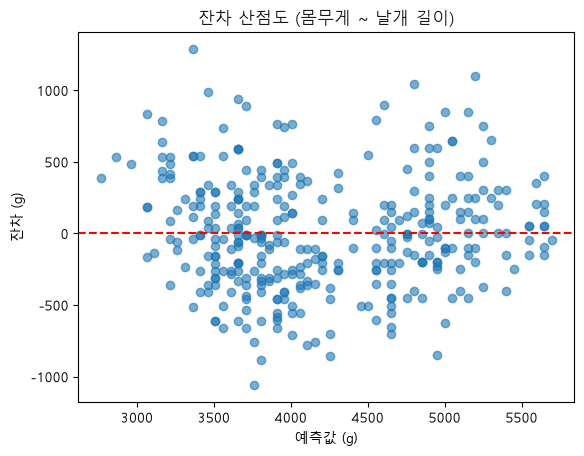

In [28]:
# 문제 5 · Q3
plt.scatter(fitted, resid, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.title('잔차 산점도 (몸무게 ~ 날개 길이)')
plt.xlabel('예측값 (g)')
plt.ylabel('잔차 (g)')
plt.show()

### Q4 · 등분산성을 숫자로 검정해 봅시다

- **브루쉬-페이건 검정**으로 등분산성을 확인하세요.

- H₀는 "등분산이다"입니다. p-값이 0.05보다 작으면 이분산을 의심합니다.

- 판정 결과를 문장으로 함께 출력하세요.

- `💡 힌트` `het_breuschpagan(잔차, model.model.exog)`는
  `(LM통계량, LM p-값, F통계량, F p-값)`을 돌려줍니다.

In [29]:
# 문제 5 · Q4

lm, lm_p, f, f_p = het_breuschpagan(resid, model.model.exog)
print(f"Breusch-Pagan LM = {lm:.3f}, p = {lm_p:.4f}")
print("이분산 의심 (등분산 기각)" if lm_p < 0.05 else "등분산 가정 기각 못함 → 등분산성 만족")

Breusch-Pagan LM = 2.158, p = 0.1418
등분산 가정 기각 못함 → 등분산성 만족


### Q5 · 문제가 있는 모형과 나란히 비교해 봅시다

- **비교군**으로 `body_mass_g ~ bill_length_mm` 모형을 적합해 `model_bill`로 저장하세요.

- 두 모형의 잔차 산점도를 **나란히** 그리세요.

- 두 모형의 브루쉬-페이건 p-값을 **함께 출력**해 비교하세요.

- `💡 힌트` `fig, ax = plt.subplots(1, 2, figsize=(12, 4))`로 두 그림을 옆으로 배치할 수 있습니다.

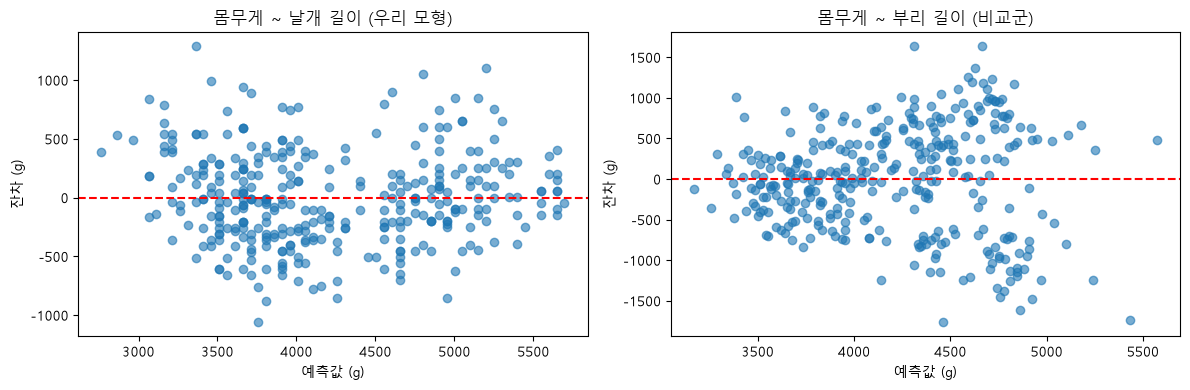

우리 모형 (날개) : BP p = 0.1418 → 등분산 OK
비교군   (부리) : BP p = 9.95e-19 → 이분산 의심
R² 비교 : 날개 0.759 vs 부리 0.354


In [31]:
# 문제 5 · Q5

pen_bill = penguins.dropna(subset=['bill_length_mm', 'body_mass_g'])
model_bill = smf.ols('body_mass_g ~ bill_length_mm', data=pen_bill).fit()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, m, title in zip(ax, [model, model_bill],
                       ['몸무게 ~ 날개 길이 (우리 모형)', '몸무게 ~ 부리 길이 (비교군)']):
    a.scatter(m.fittedvalues, m.resid, alpha=0.6)
    a.axhline(0, color='red', linestyle='--')
    a.set_title(title)
    a.set_xlabel('예측값 (g)')
    a.set_ylabel('잔차 (g)')
plt.tight_layout()
plt.show()

bp_flip = het_breuschpagan(model.resid, model.model.exog)[1]
bp_bill = het_breuschpagan(model_bill.resid, model_bill.model.exog)[1]
print(f"우리 모형 (날개) : BP p = {bp_flip:.4f} → {'이분산 의심' if bp_flip < 0.05 else '등분산 OK'}")
print(f"비교군   (부리) : BP p = {bp_bill:.2e} → {'이분산 의심' if bp_bill < 0.05 else '등분산 OK'}")
print(f"R² 비교 : 날개 {model.rsquared:.3f} vs 부리 {model_bill.rsquared:.3f}")

### Q6 · 보고 문장으로 정리해 봅시다

- 지금까지의 결과를 종합해, 우리 회귀모형을 보고서에 어떻게 적을지 **한 문장**으로 쓰세요.

- **기울기 + 유의성 + 설명력 + 진단 결과**를 모두 담아 보세요.

In [32]:
# 문제 5 · Q6

# 보고 문장: 날개 길이는 몸무게를 유의하게 예측하며(b = 49.69 g/mm, p < 0.001), 날개가 1mm 길어질 때 몸무게가 평균 약 49.7g 늘어난다. 이 모형은 몸무게 변동의 약 75.9%를 설명하고(R² = 0.759), 잔차 진단에서 등분산성 가정도 기각되지 않았다(Breusch-Pagan p = 0.142).

### 💬 정리 · 결과를 말로 설명해 보기

- Q3·Q4에서 우리 모형의 잔차는 어떤 상태였나요? 이 결과를 근거로 문제 3·4의 해석을 신뢰할 수 있을까요?

- Q5의 두 잔차 산점도는 어떻게 달랐나요? 비교군에서 관찰된 모양을 강의에서 배운 용어로 무엇이라 부르나요?

- 비교군처럼 등분산성이 깨졌을 때, **잘못된 것은 기울기 값 자체인가요, 아니면 그 값의 통계적 해석인가요?**

- R²가 1이 아니라는 것은 설명되지 않은 변동이 남아 있다는 뜻입니다. `penguins` 안에서 몸무게에 영향을 줄 만한데 우리 모델이 놓치고 있는 변수는 무엇일까요?

- 그 변수들을 모델에 함께 넣으려면 어떤 분석이 필요할까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 강의 7장은 이렇게 적었습니다 — _"파라미터 값이 잘못되었다는 뜻이 아니라, 이 값의 통계적 해석(유의성·신뢰구간)과 예측 결과를 신뢰할 수 없다는 의미"_. 세 번째 질문의 답이 여기 있습니다.

- 비교군의 잔차가 퍼지는 모양을 강의의 3케이스 그림(정규성 O·등분산 O / X·O / O·X)과 맞춰 보세요.

- 놓친 변수 후보는 문제 1의 그림에 이미 있습니다. 그 변수를 모델에 함께 넣는 분석의 이름은 다음 8장의 제목입니다.

</details>

In [ ]:
# 문제 5 · 정리

# - 우리 모형의 잔차: 0을 중심으로 뚜렷한 패턴 없이 고르게 흩어져 있고, BP 검정도 통과했습니다(p = 0.142). 그래서 문제 3·4의 기울기 해석, p-값, 신뢰구간을 신뢰할 수 있습니다.
# - 비교군의 잔차: 예측값이 커질수록 잔차가 넓어지는 깔때기 모양입니다. 이것을 이분산성(heteroscedasticity), 즉 등분산성 위배라고 부릅니다. 강의의 3케이스 그림 중 "정규성 O · 등분산 X"에 해당합니다.
# - 등분산성이 깨지면 무엇이 잘못되나: 기울기 값 자체(최소제곱 추정치)가 틀린 것이 아닙니다. 신뢰할 수 없는 것은 그 값의 통계적 해석, 즉 표준오차, p-값, 신뢰구간과 예측 구간입니다.
# - 모델이 놓친 변수: 종(species)과 성별(sex)이 대표적입니다. 문제 1에서 봤듯이 Gentoo는 다른 종보다 확연히 크고, 수컷이 암컷보다 무겁습니다. 부리 길이와 두께도 후보입니다.
# - 그 변수들을 함께 넣는 방법: 설명변수를 여러 개 쓰는 다중회귀분석(8장)이 필요합니다. 예를 들어 body_mass_g ~ flipper_length_mm + C(species) + C(sex)처럼 범주형 변수는 더미변수로 넣습니다.